# Chapter 10

Python version of the R code for Chapter 10 of *In All Likelihood* (Pawitan, 2001).

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

from helpers import DATA, li, coef_table

## Example 10.1 (`EX10-1.R`)

Highly stratified data.

support of sigma2=1 0.007315017033707565
RSS= 18.086000000000002


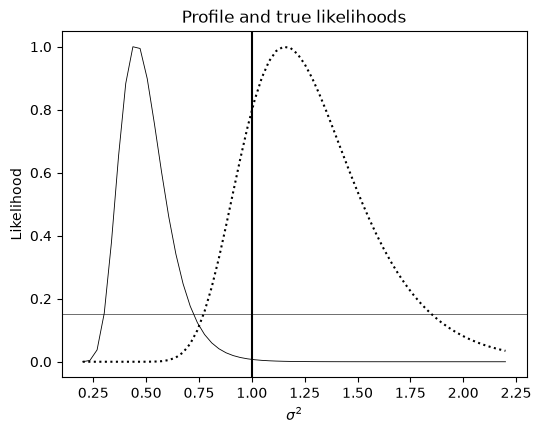

In [2]:
mat = np.loadtxt(DATA / "2way.dat")
n = mat.shape[0]
mu = mat[:, 0]
x = mat[:, 1:3]
xmean = x.mean(axis=1)
rss = np.sum((x - xmean[:, None]) ** 2)

sig2 = np.linspace(.2, 2.2, 60)
loglik = -n * np.log(sig2) - rss / 2 / sig2

s2 = rss / (2 * n)
llmax = -n * np.log(s2) - rss / 2 / s2
s2 = 1
ll1 = -n * np.log(s2) - rss / 2 / s2

print("support of sigma2=1", np.exp(ll1 - llmax))
print("RSS=", rss)
like = np.exp(loglik - loglik.max())

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(sig2, like, "k-", lw=0.6)

# 'true' likelihood: using true means
loglik = -n * np.log(sig2) - np.sum((x - mu[:, None]) ** 2) / 2 / sig2
like4 = np.exp(loglik - loglik.max())
ax.plot(sig2, like4, "k:", lw=1.5)
ax.axhline(.15, color="k", lw=0.4)
ax.axvline(1, color="k")
ax.set_xlabel(r"$\sigma^2$")
ax.set_ylabel("Likelihood")
ax.set_title("Profile and true likelihoods")
plt.show()

## Example 10.1 continued (`EX10-1C.R`)

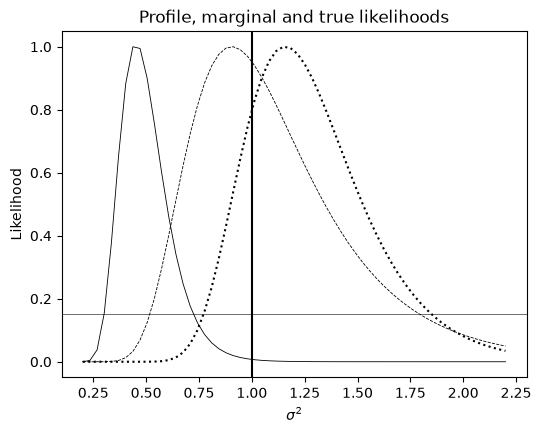

In [3]:
mat = np.loadtxt(DATA / "2way.dat")
n = mat.shape[0]
mu = mat[:, 0]
x = mat[:, 1:3]
xmean = x.mean(axis=1)

sig2 = np.linspace(.2, 2.2, 60)
loglik = -n * np.log(sig2) - np.sum((x - xmean[:, None]) ** 2) / 2 / sig2
like = np.exp(loglik - loglik.max())

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(sig2, like, "k-", lw=0.6)

# marginal likelihood
y = (x[:, 0] - x[:, 1]) / np.sqrt(2)
loglik2 = -n / 2 * np.log(sig2) - np.sum(y ** 2) / 2 / sig2
like2 = np.exp(loglik2 - loglik2.max())
ax.plot(sig2, like2, "k--", lw=0.6)

# true likelihood: using true means
loglik = -n * np.log(sig2) - np.sum((x - mu[:, None]) ** 2) / 2 / sig2
like4 = np.exp(loglik - loglik.max())
ax.plot(sig2, like4, "k:", lw=1.5)
ax.axhline(.15, color="k", lw=0.4)
ax.axvline(1, color="k")
ax.set_xlabel(r"$\sigma^2$")
ax.set_ylabel("Likelihood")
ax.set_title("Profile, marginal and true likelihoods")
plt.show()

## Example 10.2 (`EX10-2.R`)

Highly stratified binomial.

In [4]:
y = np.loadtxt(DATA / "binhigh.dat").ravel()
n = len(y) // 2
strata = np.tile(np.arange(1, n + 1), 2)
treat = np.repeat([0, 1], [n, n])

# Many strata have all-zero or all-one responses, so the fit is numerically
# unstable (statsmodels warns about this; the warnings are silenced here).
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    yreg = smf.glm("y ~ treat + C(strata)",
                   data=pd.DataFrame({"y": y, "treat": treat, "strata": strata}),
                   family=sm.families.Binomial()).fit()
print("constant and treatment estimates")
print(coef_table(yreg).loc[["Intercept", "treat"]])

# verifying the conditional analysis in Section 10.5, page 285:
y01 = y.reshape(2, n).T  # column 0: treat=0, column 1: treat=1
disc = y01[np.abs(y01[:, 0] - y01[:, 1]) > 0.5]  # discordant pairs
p = disc[:, 1].sum() / disc.shape[0]
print(np.log(p / (1 - p)))
a = sm.GLM(disc[:, 1], np.ones(disc.shape[0]), family=sm.families.Binomial()).fit()
print(a.summary(xname=["(Intercept)"]))

constant and treatment estimates
            Estimate    Std. Error     value  Pr(>|value|)
Intercept -26.697803  80802.022110 -0.000330      0.999736
treat       3.052113      0.697823  4.373765      0.000012
1.526056303495049
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                   28
Model:                            GLM   Df Residuals:                       27
Model Family:                Binomial   Df Model:                            0
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -13.138
Date:                Sat, 10 Oct 2026   Deviance:                       26.276
Time:                        17:55:41   Pearson chi2:                     28.0
No. Iterations:                     4   Pseudo R-squ. (CS):              0.000
Covariance Type:            nonrobust                        

## Example 10.9 (`EX10-9.R`)

Normal mean.

95% t-interval -0.6004536575938353 5.9277263848665624
[-0.2146283   5.54190103]
[-0.34733612  5.67460885]
[-0.72815338  6.05542611]


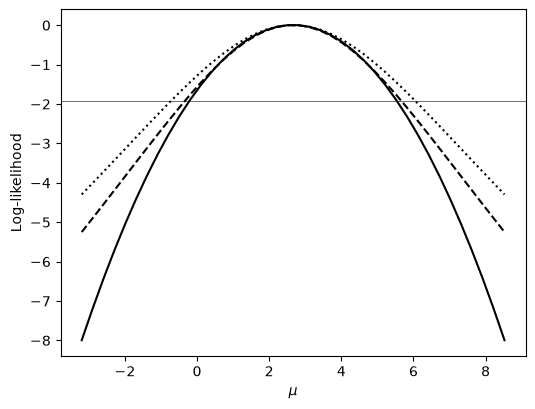

In [5]:
x = np.array([-5.3, -4.5, -1.0, -0.7, 3.7, 3.9, 4.2, 5.5, 6.8, 7.4, 9.3])
n = len(x)
mx = x.mean()
sx = np.std(x, ddof=1)
df = n - 1
se = sx / np.sqrt(n)
alp = 0.05
print("95% t-interval", mx + stats.t.ppf(alp / 2, df) * se, mx - stats.t.ppf(alp / 2, df) * se)

th = np.linspace(mx - 4 * se, mx + 4 * se, 40)

cut = np.exp(-stats.chi2.ppf(1 - alp, 1) / 2)
tstat = np.sqrt(n) * (mx - th) / sx
llnorm = -n * (mx - th) ** 2 / 2 / sx ** 2
llnorm = llnorm - llnorm.max()
print(li(th, np.exp(llnorm), cut))
llp = -n / 2 * np.log(1 + tstat ** 2 / (n - 1))  # PROFILE
llp = llp - llp.max()
print(li(th, np.exp(llp), cut))
llm = -(n - 2) / 2 * np.log(1 + tstat ** 2 / (n - 1))  # MODIFIED PROFILE
llm = llm - llm.max()
print(li(th, np.exp(llm), cut))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(th, llnorm, "k-")
ax.plot(th, llp, "k--")
ax.plot(th, llm, "k:", lw=1.5)
ax.axhline(-stats.chi2.ppf(1 - alp, 1) / 2, color="k", lw=0.4)
ax.set_xlabel(r"$\mu$")
ax.set_ylabel("Log-likelihood")
plt.show()

## Figure 10.3 (`FIG10-3.R`)

1.5040773967762742 -2.1972245773362196
2.538973871058276 -2.9444389791664407


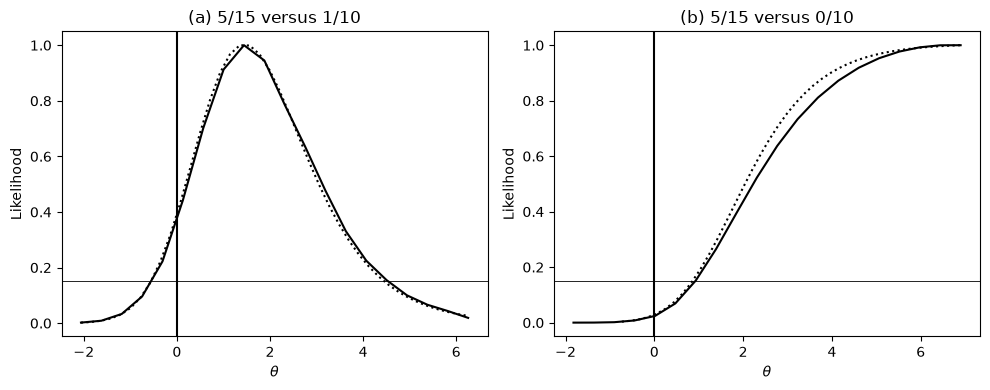

In [6]:
def fun1(theta, eta):
    a = np.exp(theta + eta)
    b = np.exp(eta)
    return x * theta + (x + y) * eta - m * np.log(1 + a) - n * np.log(1 + b)


def conditional_likelihood(th):
    """Likelihood of theta from the (noncentral) hypergeometric distribution."""
    xx = np.arange(0, x + y + 1)
    numx = stats.hypergeom.pmf(x, m + n, m, x + y)
    numxx = stats.hypergeom.pmf(xx, m + n, m, x + y)
    l1 = np.array([numx * np.exp(theta * x) / np.sum(numxx * np.exp(theta * xx))
                   for theta in th])
    return l1 / l1.max()


fig, axes = plt.subplots(1, 2, figsize=(10, 4))

x, m = 5, 15
y, n = 1, 10

that = np.log(x / (m - x) * (n - y) / y)
se2 = 1 / x + 1 / (m - x) + 1 / y + 1 / (n - y)
se = np.sqrt(se2)

ehat = np.log(y / (n - y))
print(that, ehat)

th = np.linspace(that - 3 * se, that + 4 * se, 20)
et = np.linspace(ehat - 4, ehat + 2, 20)

ll = fun1(th[:, None], et[None, :])
like = np.exp(ll - ll.max())
lik1 = like.max(axis=1)  # profile likelihood

ax = axes[0]
ax.plot(th, lik1, "k-")
ax.axhline(.15, color="k", lw=0.6)
ax.axvline(0, color="k")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("(a) 5/15 versus 1/10")

# ...............     hypergeometric computation:
th = np.linspace(that - 3 * se, that + 4 * se, 40)
ax.plot(th, conditional_likelihood(th), "k:", lw=1.5)

# ........................       second example: an extreme case
x, m = 6, 15
y, n = 0, 10

y = .5  # only to compute estimates
that = np.log(x / (m - x) * (n - y) / y)
se2 = 1 / x + 1 / (m - x) + 1 / y + 1 / (n - y)
se = np.sqrt(se)  # as in the original code

ehat = np.log(y / (n - y))
print(that, ehat)

th = np.linspace(that - 4 * se, that + 4 * se, 20)
et = np.linspace(ehat - 6, ehat + 2, 20)

y = 0  # the actual value of y
ll = fun1(th[:, None], et[None, :])
like = np.exp(ll - ll.max())
lik1 = like.max(axis=1)  # profile likelihood

ax = axes[1]
ax.plot(th, lik1, "k-")
ax.axhline(.15, color="k", lw=0.6)
ax.axvline(0, color="k")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("(b) 5/15 versus 0/10")

# hypergeometric computation:
th = np.linspace(that - 3 * se, that + 4 * se, 40)
ax.plot(th, conditional_likelihood(th), "k:", lw=1.5)

fig.tight_layout()
plt.show()